# Exploratory data analysis of the Johnston's organ subgraph

### CRISP-DM phases 2 and 3, data understanding and preparation

**Trabajo de Integración Curricular**, *Bio-Inspired Neuromorphic Coding for Efficient Edge AI with Spiking Neural Networks*

---

## Context

This notebook works through phases 2 (data understanding) and 3 (data preparation) of the CRISP-DM framework as they apply to *Component 1* of the project. We extract and characterize the subgraph of the **Johnston's organ (JO) auditory circuit** from the whole-brain connectome of adult *Drosophila melanogaster* released by the **FlyWire** consortium (Dorkenwald et al., 2024; Schlegel et al., 2024; Eckstein et al., 2024).

That subgraph is the **biological topology** that later drives a spiking neural network trained with STDP, and which gets compared against an artificial **control network** of matched statistical properties. So the stage carries weight. *A badly extracted subgraph would invalidate every experiment downstream*, which is exactly why KDD puts selection, cleaning and transformation ahead of any modeling.

## What this notebook does

**Phase 2, data understanding**
1. Load the FlyWire connectome (annotations and connections) and describe it globally.
2. Identify the Johnston's organ neurons following the taxonomy of Schlegel et al. (2024), with `super_class = sensory`, `class = mechanosensory` and `sub_class = auditory`.
3. Produce the three diagnostic explorations the methodology asks for, covering the cell types of the subgraph, the synaptic weight distribution and the predicted neurotransmitter.

**Phase 3, data preparation**
4. Build the node set (JO neurons plus second-order AMMC interneurons).
5. Filter the connections by synaptic weight threshold, justifying the cut with data.
6. Build the directed graph with `NetworkX` and extract a broad set of **topological metrics** (degrees, centrality, reciprocity, components, clustering, communities, E/I balance).
7. Draw the subgraph and build the artificial **control network** (configuration model and Erdős–Rényi).
8. Persist the deliverables in open formats.

> **Methodological note.** The data are the downloadable files of the **FlyWire Codex** portal (`classification` and `connections`), chosen so that results stay directly comparable with Shiu et al. (2024) and with the Eon Systems emulation (Wissner-Gross, 2026).

## 0. Environment setup

### 0.1. Installing the libraries

The notebook leans on the scientific Python stack justified in Chapter 2 of the document.

| Library | Role in this notebook |
|---|---|
| `pandas`, `numpy` | Loading and manipulating the connectome tables. |
| `networkx` | Topological analysis of the subgraph (degrees, centrality, communities). |
| `matplotlib`, `seaborn` | Figures (histograms, distributions, graph *layout*). |
| `scipy` | Descriptive statistics and auxiliary tests. |
| `python-louvain` | Community detection (Louvain modularity). |

The cell below installs the dependencies. If they are already available in the environment, `pip` just verifies them and moves on.

In [1]:
# Dependency install. Idempotent, so nothing happens if the packages are already there.
%pip install -q pandas numpy networkx matplotlib seaborn scipy python-louvain

Note: you may need to restart the kernel to use updated packages.


### 0.2. Imports and global parameters

Here we fix the paths, a **random seed** so that the work is reproducible (the methodology requires every stochastic process to be replayable), and a single visual style shared by all the figures.

> **Before you run this.** `data/classification.csv.gz` ships with the repository. The second input, `connections_buhmann_no_threshold.csv.gz`, is far too large to distribute here, so download it from the FlyWire Codex download page (<https://codex.flywire.ai/api/download>) and drop it into `01-data-understanding/data/`. The existence check printed by the next cell tells you whether both files are where the notebook expects them.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# --- Reproducibility ---
SEED = 42
rng = np.random.default_rng(SEED)

# --- Paths, relative to the notebook's own directory (01-data-understanding/) ---
DATA_DIR = Path("data")
OUT_DIR = Path("outputs")                   # deliverables produced by this notebook
OUT_DIR.mkdir(parents=True, exist_ok=True)

ANNOT_FILE = DATA_DIR / "classification.csv.gz"
CONN_FILE = DATA_DIR / "connections_buhmann_no_threshold.csv.gz"

# --- One visual style for the whole document ---
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "axes.titleweight": "bold",
    "font.size": 11,
})
# Consistent palette for the two groups of neurons in the subgraph.
COL_JO = "#2E86AB"      # Johnston's organ sensory neurons
COL_AMMC = "#C73E1D"    # second-order interneurons (AMMC and neighbors)

print("Environment ready.")
print(f"  pandas    {pd.__version__}")
print(f"  numpy     {np.__version__}")
print(f"  networkx  {nx.__version__}")
print(f"  Raw data present?  classification={ANNOT_FILE.exists()}  connections={CONN_FILE.exists()}")

Environment ready.
  pandas    3.0.3
  numpy     2.4.6
  networkx  3.6.1
  Raw data present?  classification=True  connections=True


# Phase 2, data understanding

> *"Before starting, it pays to map what the connectome holds and how far each piece can be trusted."*

Nothing is transformed yet at this stage. We load, inspect and describe. The point is to reach Phase 3 with informed decisions instead of blind ones.

## 2.1. Loading the connectome tables

FlyWire is distributed from Codex in several tables, two of which we use here.

- **`classification.csv`**, one row per neuron, carrying the hierarchical classification (`super_class → class → sub_class`), the side (`side`), the nerve (`nerve`) and the lineage.
- **`connections.csv`**, one row per connection *(pre, post, neuropil)*, with the number of synaptic contacts (`syn_count`) and the predicted neurotransmitter (`nt_type`).

> The `connections` version we use is `connections_buhmann_no_threshold`. It keeps **every** predicted connection, with no threshold applied upstream, which leaves the choice of threshold to us in Phase 3 and lets us base it on evidence.

In [3]:
# --- Annotation table (one row per neuron) ---
annot = pd.read_csv(ANNOT_FILE, low_memory=False)

print(f"Annotations: {annot.shape[0]:,} neurons × {annot.shape[1]} columns")
print(f"Columns: {list(annot.columns)}\n")
annot.head()

Annotations: 139,255 neurons × 8 columns
Columns: ['root_id', 'flow', 'super_class', 'class', 'sub_class', 'hemilineage', 'side', 'nerve']



,root_id,flow,super_class,class,sub_class,hemilineage,side,nerve
0,720575940599457990,intrinsic,optic,optic_lobe_intrinsic,t4_neuron,NaN,right,NaN
1,720575940599763910,intrinsic,optic,optic_lobe_intrinsic,t5_neuron,NaN,right,NaN
2,720575940600623020,intrinsic,optic,optic_lobe_intrinsic,distal_medulla,NaN,right,NaN
3,720575940602309600,afferent,sensory_ascending,AN,SA_DMT_DMetaN,NaN,right,CV
4,720575940602564320,intrinsic,central,Kenyon_Cell,KCg,MBp4,right,NaN


In [4]:
# --- Connection table (one row per pre→post→neuropil connection) ---
# The file holds ~17 M rows, so we load compact dtypes to keep memory in check.
conn = pd.read_csv(
    CONN_FILE,
    dtype={
        "pre_root_id": "int64",
        "post_root_id": "int64",
        "neuropil": "category",
        "syn_count": "int32",
        "nt_type": "category",
    },
)

print(f"Connections: {conn.shape[0]:,} rows × {conn.shape[1]} columns")
print(f"Approximate memory: {conn.memory_usage(deep=True).sum() / 1e6:,.0f} MB\n")
conn.head()

Connections: 16,847,997 rows × 5 columns
Approximate memory: 371 MB



,pre_root_id,post_root_id,neuropil,syn_count,nt_type
0,720575940629970489,720575940631267655,AVLP_R,7,GABA
1,720575940623828999,720575940612348950,SLP_R,4,GLUT
2,720575940624078484,720575940616950161,SMP_R,2,ACH
3,720575940629583345,720575940620324735,SMP_L,2,GLUT
4,720575940605876866,720575940606514878,LAL_R,15,GABA


## 2.2. Global characterization of the connectome

Before isolating the Johnston's organ it helps to place it inside the whole brain. How many neurons are there in total, and how do they split across **super-classes** (sensory, central, optic, and so on)? The answer gives a sense of the scale of the problem and of how much of the connectome the sensory subsystem accounts for.

FlyWire connectome at a glance
---------------------------------------------
Annotated neurons:                 139,255
Connections (pre→post→npil rows):  16,847,997
Total synaptic contacts:           54,492,922
Distinct neuropils:                79
Predicted neurotransmitters:       ['ACH', 'DA', 'GABA', 'GLUT', 'OCT', 'SER']


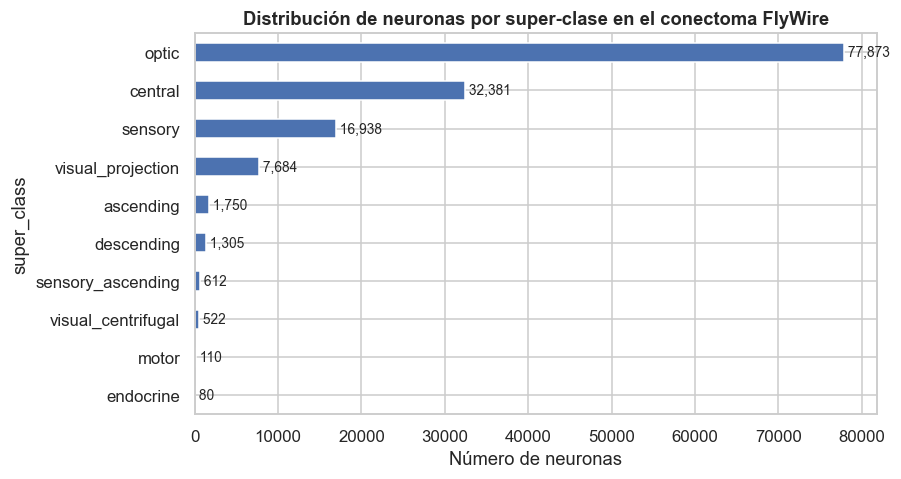

super_class
optic                 77873
central               32381
sensory               16938
visual_projection      7684
ascending              1750
descending             1305
sensory_ascending       612
visual_centrifugal      522
motor                   110
endocrine                80
Name: count, dtype: int64

In [5]:
n_neurons = len(annot)
n_conn_rows = len(conn)
total_syn = int(conn["syn_count"].sum())

print("FlyWire connectome at a glance")
print("-" * 45)
print(f"Annotated neurons:                 {n_neurons:,}")
print(f"Connections (pre→post→npil rows):  {n_conn_rows:,}")
print(f"Total synaptic contacts:           {total_syn:,}")
print(f"Distinct neuropils:                {conn['neuropil'].nunique()}")
print(f"Predicted neurotransmitters:       {list(conn['nt_type'].cat.categories)}")

# Distribution by super-class
super_counts = annot["super_class"].value_counts(dropna=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
super_counts.plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_xlabel("Number of neurons")
ax.set_ylabel("super_class")
ax.set_title("Neurons per super-class in the FlyWire connectome")
ax.invert_yaxis()
for i, v in enumerate(super_counts.values):
    ax.text(v, i, f" {v:,}", va="center", fontsize=9)
fig.savefig(OUT_DIR / "fig01_connectome_superclass_distribution.png")
plt.show()

super_counts

## 2.3. Identifying the Johnston's organ

The Johnston's organ (JO) is the main mechanosensory organ of *Drosophila*, housed in the second antennal segment. Kamikouchi et al. (2009) described five functional subgroups, JO-A through JO-E. **JO-A and JO-B** respond to vibrations between 10 and 1000 Hz and work as sound sensors, while the remaining ones encode static deflection (gravity and wind).

Following the taxonomy of Schlegel et al. (2024), the auditory JO neurons are isolated with three hierarchical conditions on the annotation table:

$$\texttt{super\_class} = \text{sensory} \;\land\; \texttt{class} = \text{mechanosensory} \;\land\; \texttt{sub\_class} = \text{auditory}$$

Since the experiment is one of **auditory classification**, we restrict the subgraph to the `auditory` sub-class, which groups JO-A together with JO-B. We validate the selection by comparing the resulting count against the expected anatomical range (around 500 sensory neurons in the full JO, of which the auditory ones are a fraction).

In [6]:
# Mechanosensory neurons, the context the JO belongs to
mechano = annot[(annot["super_class"] == "sensory") & (annot["class"] == "mechanosensory")]
print("Mechanosensory sub-classes available (context for the JO):")
print(mechano["sub_class"].value_counts(dropna=False).to_string())

# --- Auditory Johnston's organ filter (JO-A + JO-B) ---
JO_SUBCLASSES = ["auditory"]
jo_mask = (
    (annot["super_class"] == "sensory")
    & (annot["class"] == "mechanosensory")
    & (annot["sub_class"].isin(JO_SUBCLASSES))
)
jo_neurons = annot[jo_mask].copy()
jo_ids = set(jo_neurons["root_id"].astype(np.int64))

print("\n" + "=" * 45)
print(f"Auditory JO neurons found: {len(jo_ids)}")
print("=" * 45)
print("\nBreakdown by side:")
print(jo_neurons["side"].value_counts(dropna=False).to_string())
print("\nBreakdown by nerve:")
print(jo_neurons["nerve"].value_counts(dropna=False).to_string())
jo_neurons.head()

Mechanosensory sub-classes available (context for the JO):
sub_class
eye_bristle                        1113
wind_gravity                        486
auditory                            393
head_bristle                        304
grooming                            205
NaN                                  97
taste_peg                            75
labial_nerve_sensory_descending       1

Auditory JO neurons found: 393

Breakdown by side:
side
left     214
right    179

Breakdown by nerve:
nerve
AN    393


,root_id,flow,super_class,class,sub_class,hemilineage,side,nerve
244,720575940605219500,afferent,sensory,mechanosensory,auditory,NaN,left,AN
1111,720575940610236740,afferent,sensory,mechanosensory,auditory,NaN,right,AN
2002,720575940613006590,afferent,sensory,mechanosensory,auditory,NaN,left,AN
2551,720575940614795410,afferent,sensory,mechanosensory,auditory,NaN,left,AN
2729,720575940615241010,afferent,sensory,mechanosensory,auditory,NaN,right,AN


## 2.4. Delimiting the subgraph and exploring it

The JO sensory neurons do not form a circuit on their own. They project onto interneurons of the **AMMC** (*Antennal Mechanosensory and Motor Center*), which is where processing begins. To give the subgraph usable dynamics we add the **first-order postsynaptic partners** of the JO neurons, that is, the second order of the circuit. This sets the boundary of the subgraph. Filtering by synaptic weight comes later, in Phase 3.

On that delimited subgraph we run the **three diagnostic explorations** the methodology requires before any threshold is fixed.

1. **Cell types** present in the subgraph.
2. **Synaptic weight distribution** (number of contacts per connection).
3. **Predicted neurotransmitter distribution** per connection.

In [7]:
# --- Postsynaptic partners of the JO neurons (second-order interneurons) ---
jo_outgoing = conn[conn["pre_root_id"].isin(jo_ids)]
partners = set(jo_outgoing["post_root_id"].astype(np.int64)) - jo_ids

# Node set of the subgraph = JO ∪ second-order partners
nodes = jo_ids | partners

# Connections internal to the subgraph (no threshold yet)
conn_sub = conn[conn["pre_root_id"].isin(nodes) & conn["post_root_id"].isin(nodes)].copy()

# A single real pre→post connection can be split across several neuropils (several rows).
# The synaptic weight of the connection is the SUM of contacts over all neuropils.
# By Dale's principle nt_type is a property of the presynaptic neuron, so aggregating
# it stays consistent.
edges_agg = (
    conn_sub.groupby(["pre_root_id", "post_root_id"], observed=True)
    .agg(syn_count=("syn_count", "sum"), nt_type=("nt_type", "first"))
    .reset_index()
)

print(f"JO neurons (sensory):                       {len(jo_ids)}")
print(f"Second-order partners (AMMC and neighbors): {len(partners)}")
print(f"Total subgraph nodes:                       {len(nodes)}")
print("-" * 45)
print(f"Internal connection rows (pre→post→neuropil):    {len(conn_sub):,}")
print(f"Unique connections (pre→post) after aggregation: {len(edges_agg):,}")
print(f"  → multi-neuropil collapse factor: {len(conn_sub) / len(edges_agg):.2f}×")

JO neurons (sensory):                       393
Second-order partners (AMMC and neighbors): 972
Total subgraph nodes:                       1365
---------------------------------------------
Internal connection rows (pre→post→neuropil):    108,374
Unique connections (pre→post) after aggregation: 71,621
  → multi-neuropil collapse factor: 1.51×


### Exploration 1. Cell types present in the subgraph

The 393 JO neurons are all `auditory` by construction, so nothing is learned from them alone. What is informative is **which neuron types receive their projection**. Those second-order partners are what tell us whether the subgraph really drains into the AMMC and associated areas, as the anatomy predicts (Kamikouchi et al., 2009; Patella & Wilson, 2018).

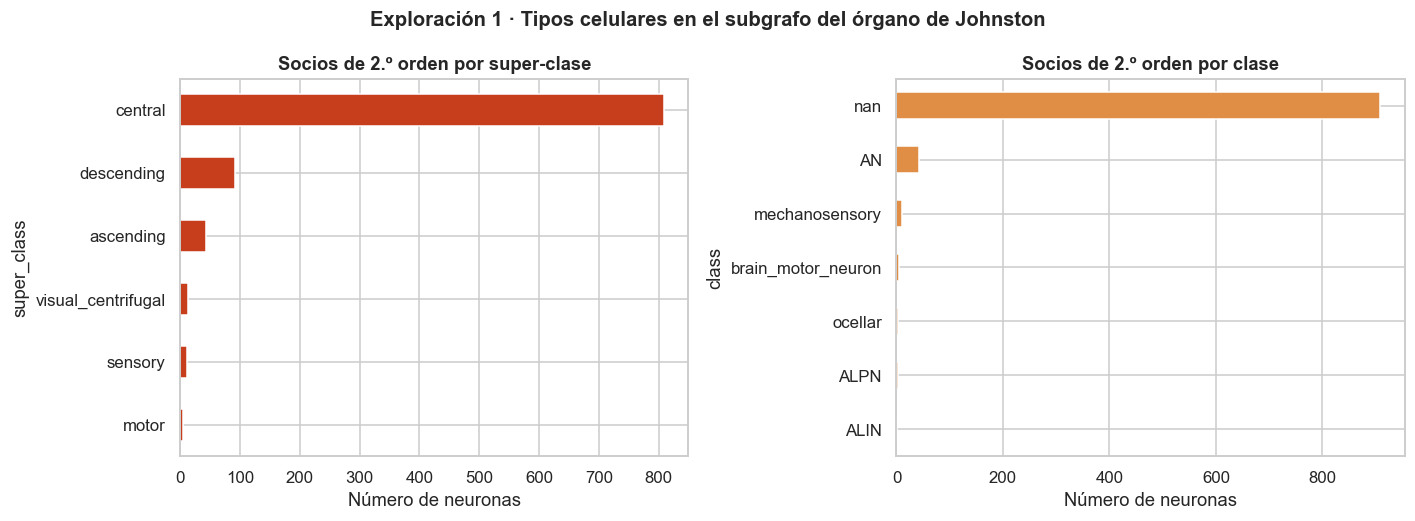

Unclassified partners (empty super_class): 0 (0.0%)


In [8]:
# Per-node attribute table for the subgraph (classification + JO flag)
node_info = (
    annot.set_index("root_id")
    .reindex(sorted(nodes))
    .assign(is_jo=lambda d: d.index.isin(jo_ids))
)
node_info.index.name = "root_id"

# Super-class distribution among the second-order (non-JO) partners
partner_info = node_info[~node_info["is_jo"]]
super_partners = partner_info["super_class"].value_counts(dropna=False).head(12)
class_partners = partner_info["class"].value_counts(dropna=False).head(12)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
super_partners.plot(kind="barh", ax=axes[0], color=COL_AMMC)
axes[0].set_title("Second-order partners by super-class")
axes[0].set_xlabel("Number of neurons"); axes[0].invert_yaxis()

class_partners.plot(kind="barh", ax=axes[1], color="#E08E45")
axes[1].set_title("Second-order partners by class")
axes[1].set_xlabel("Number of neurons"); axes[1].invert_yaxis()

fig.suptitle("Exploration 1 · Cell types in the Johnston's organ subgraph",
             fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "fig02_jo_cell_types.png")
plt.show()

n_unclassified = partner_info["super_class"].isna().sum()
print(f"Unclassified partners (empty super_class): {n_unclassified} "
      f"({100*n_unclassified/len(partner_info):.1f}%)")

### Exploration 2. Synaptic weight distribution

Synaptic weight (`syn_count`, the number of contacts making up a connection) is the main proxy for how reliable a FlyWire connection is. Connections built on very few contacts are the ones most likely to be segmentation noise. The distribution has a long tail, with many weak connections and a handful of very strong ones, so a logarithmic scale is the readable way to show it. This figure is what justifies the filtering threshold fixed in Phase 3.

Descriptive statistics of the synaptic weight (contacts per connection):
count    71621.000000
mean         5.949191
std         12.770526
min          1.000000
50%          2.000000
75%          5.000000
90%         14.000000
95%         24.000000
99%         60.000000
max        347.000000


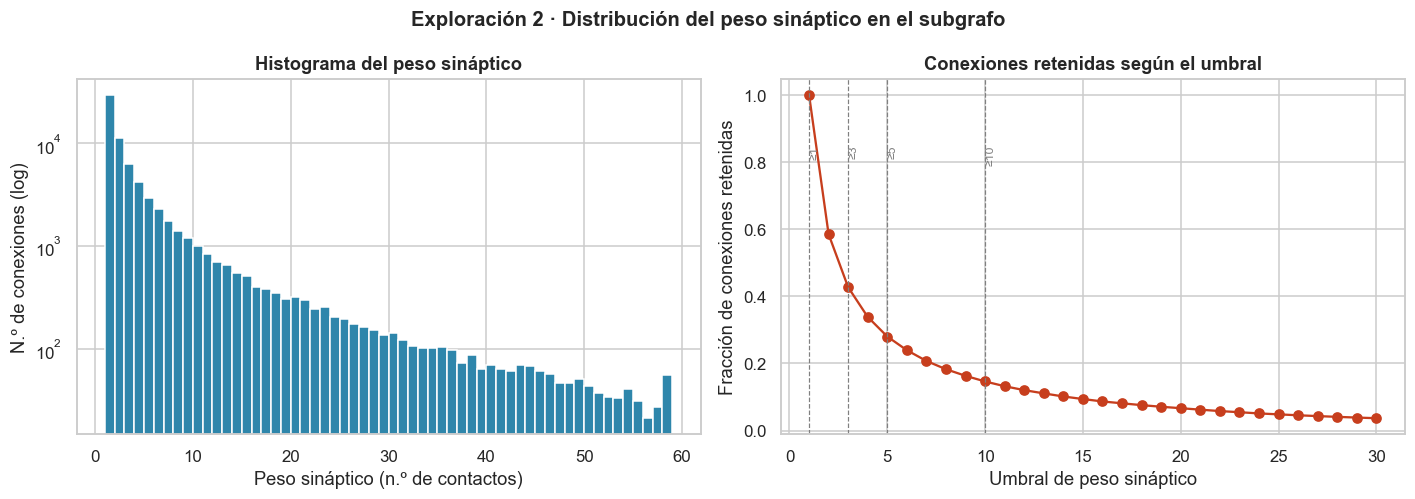

  Connections with weight ≥  1:  71,621  (100.0%)
  Connections with weight ≥  3:  30,569  ( 42.7%)
  Connections with weight ≥  5:  20,059  ( 28.0%)
  Connections with weight ≥ 10:  10,475  ( 14.6%)


In [9]:
w = edges_agg["syn_count"].to_numpy()

print("Descriptive statistics of the synaptic weight (contacts per connection):")
print(pd.Series(w).describe(percentiles=[.5, .75, .9, .95, .99]).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# Histogram on a log y scale
axes[0].hist(w, bins=np.arange(1, 60, 1), color=COL_JO, edgecolor="white")
axes[0].set_yscale("log")
axes[0].set_xlabel("Synaptic weight (number of contacts)")
axes[0].set_ylabel("Number of connections (log)")
axes[0].set_title("Synaptic weight histogram")

# Survival function (fraction of connections with weight >= x)
xs = np.arange(1, 31)
surv = [(w >= t).mean() for t in xs]
axes[1].plot(xs, surv, "o-", color=COL_AMMC)
for t in (1, 3, 5, 10):
    axes[1].axvline(t, ls="--", lw=0.8, color="gray")
    axes[1].text(t, 0.85, f"≥{t}", rotation=90, va="top", fontsize=8, color="gray")
axes[1].set_xlabel("Synaptic weight threshold")
axes[1].set_ylabel("Fraction of connections retained")
axes[1].set_title("Connections retained by threshold")

fig.suptitle("Exploration 2 · Synaptic weight distribution in the subgraph",
             fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "fig03_synaptic_weight_distribution.png")
plt.show()

for t in (1, 3, 5, 10):
    print(f"  Connections with weight ≥ {t:>2}: {int((w >= t).sum()):>7,}  ({100*(w>=t).mean():5.1f}%)")

### Exploration 3. Predicted neurotransmitter distribution

Eckstein et al. (2024) predicted the neurotransmitter of every synapse from the electron microscopy images, reaching around 87 % accuracy per synapse and around 94 % per neuron over six neurotransmitters (ACH, GABA, GLUT, SER, DA, OCT). That prediction is what lets us assign **excitatory or inhibitory polarity** to each connection, and without it the SNN cannot be built.

> **On confidence scores.** The methodology suggests examining the neurotransmitter *confidence score*. The aggregated Codex export (`connections`) carries no per-connection confidence column, since that information lives in the individual synapse table. What we do instead is characterize the **categorical distribution of the predicted neurotransmitter** and use the **synaptic weight from Exploration 2 as a proxy for the reliability** of the connection. Recovering per-synapse confidence is flagged as future work, should the polarity filter ever need tightening.

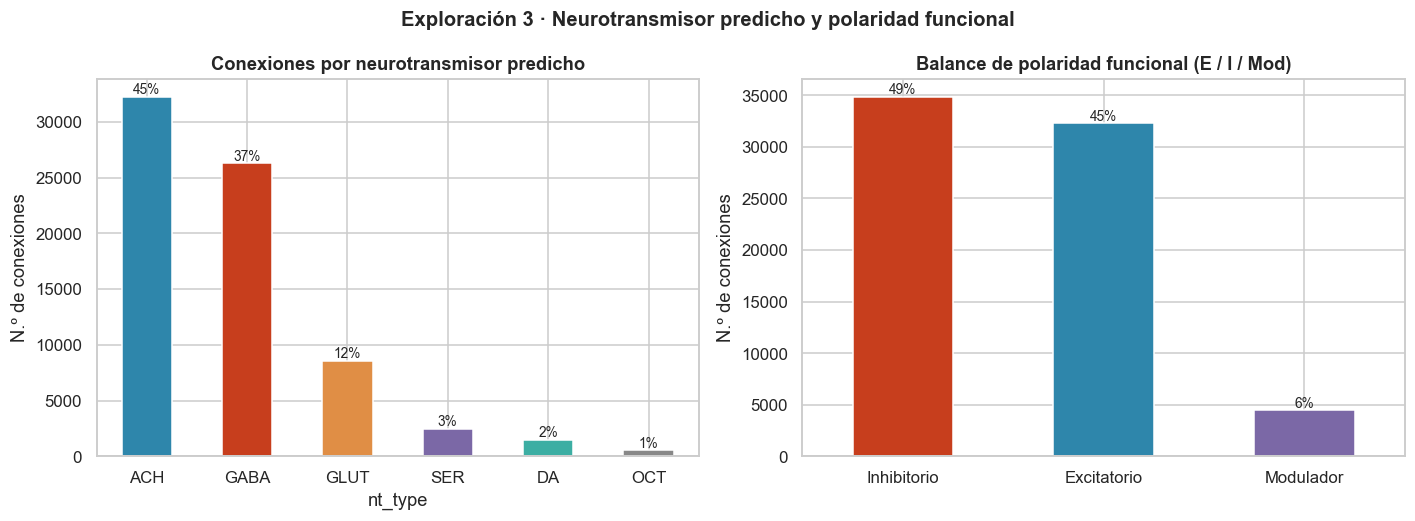

Connections per neurotransmitter:
 nt_type
ACH     32281
GABA    26297
GLUT     8578
SER      2465
DA       1470
OCT       530


In [10]:
# Connection counts per neurotransmitter, plus contacts weighted by synaptic weight
nt_by_conn = edges_agg["nt_type"].value_counts()
nt_by_syn = edges_agg.groupby("nt_type", observed=True)["syn_count"].sum().sort_values(ascending=False)

# Functional polarity in Drosophila: ACH excitatory; GABA and GLUT inhibitory;
# SER, DA and OCT modulatory (Eckstein et al., 2024).
# The label strings are kept verbatim because they are written into the exported
# edge list consumed by the phase 3 notebooks.
POLARITY = {"ACH": "Excitatory", "GABA": "Inhibitory", "GLUT": "Inhibitory",
            "SER": "Modulatory", "DA": "Modulatory", "OCT": "Modulatory"}
edges_agg["polarity"] = edges_agg["nt_type"].map(POLARITY).fillna("Unknown")
pol_counts = edges_agg["polarity"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
nt_palette = {"ACH": "#2E86AB", "GABA": "#C73E1D", "GLUT": "#E08E45",
              "SER": "#7B68A6", "DA": "#3CAEA3", "OCT": "#888888"}
bar_cols = [nt_palette.get(k, "#888") for k in nt_by_conn.index]
nt_by_conn.plot(kind="bar", ax=axes[0], color=bar_cols)
axes[0].set_title("Connections per predicted neurotransmitter")
axes[0].set_ylabel("Number of connections"); axes[0].set_xlabel("nt_type")
axes[0].tick_params(axis="x", rotation=0)
for i, v in enumerate(nt_by_conn.values):
    axes[0].text(i, v, f"{100*v/nt_by_conn.sum():.0f}%", ha="center", va="bottom", fontsize=9)

pol_cols = {"Excitatory": "#2E86AB", "Inhibitory": "#C73E1D",
            "Modulatory": "#7B68A6", "Unknown": "#bbbbbb"}
pol_counts.plot(kind="bar", ax=axes[1], color=[pol_cols[k] for k in pol_counts.index])
axes[1].set_title("Functional polarity balance (E / I / Mod)")
axes[1].set_ylabel("Number of connections"); axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
for i, v in enumerate(pol_counts.values):
    axes[1].text(i, v, f"{100*v/pol_counts.sum():.0f}%", ha="center", va="bottom", fontsize=9)

fig.suptitle("Exploration 3 · Predicted neurotransmitter and functional polarity",
             fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "fig04_neurotransmitter_polarity.png")
plt.show()

print("Connections per neurotransmitter:\n", nt_by_conn.to_string())

# Phase 3, data preparation

> *"The longest phase of the project, and the one whose decisions most need documenting."*

With the subgraph delimited and described, this phase **transforms** it into the topology the model will consume. It covers the Component 1 tasks that belong to this notebook, namely filtering by synaptic weight, building the directed graph, analyzing its topology and generating the control network. (Auditory stimulus processing and the train/val/test split belong to Component 4 and are documented in their own notebook.)

## 3.1. Filtering the subgraph by synaptic weight threshold

The methodology takes **at least 5 contacts per connection** as its reference threshold, a common choice in the FlyWire literature for discarding weak connections likely to be segmentation noise. Rather than adopt it outright, we sweep a range of thresholds and measure what each one does to the node and edge counts, so that the decision rests on evidence, as KDD asks.

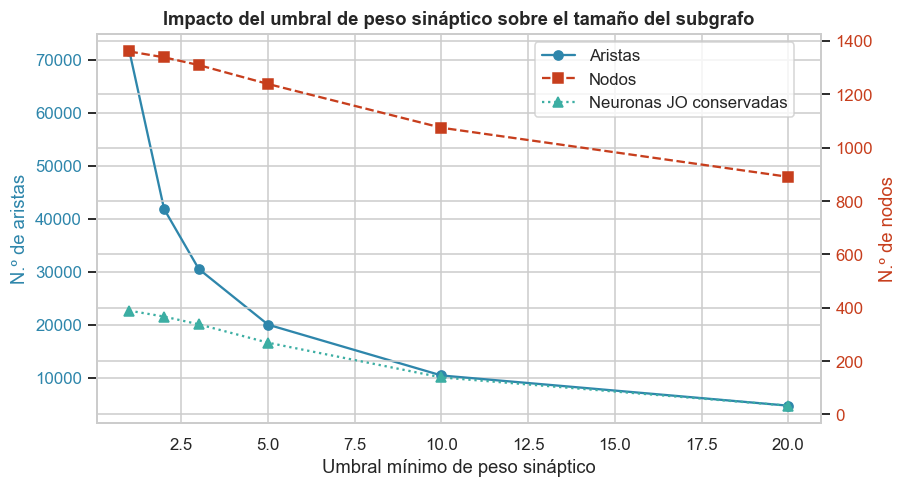

,umbral,aristas,nodos,neuronas_JO_conservadas,contactos_totales
0,1,71621,1361,389,426087
1,2,41881,1339,367,396347
2,3,30569,1310,338,373723
3,5,20059,1239,269,338013
4,10,10475,1075,139,275227
5,20,4777,891,33,198660


In [11]:
def subgraph_at_threshold(edges_df, jo_ids, min_syn):
    """Edges and nodes retained when filtering by synaptic weight >= min_syn.
    Only nodes that stay connected after the filter are kept, which is what
    guarantees the JO neurons are not left isolated."""
    e = edges_df[edges_df["syn_count"] >= min_syn]
    kept_nodes = set(e["pre_root_id"]) | set(e["post_root_id"])
    jo_kept = len(jo_ids & kept_nodes)
    return {
        "threshold": min_syn,
        "edges": len(e),
        "nodes": len(kept_nodes),
        "jo_neurons_kept": jo_kept,
        "total_contacts": int(e["syn_count"].sum()),
    }

sweep = pd.DataFrame([subgraph_at_threshold(edges_agg, jo_ids, t)
                      for t in [1, 2, 3, 5, 10, 20]])

fig, ax1 = plt.subplots(figsize=(8.5, 4.6))
ax1.plot(sweep["threshold"], sweep["edges"], "o-", color=COL_JO, label="Edges")
ax1.set_xlabel("Minimum synaptic weight threshold")
ax1.set_ylabel("Number of edges", color=COL_JO)
ax1.tick_params(axis="y", labelcolor=COL_JO)
ax2 = ax1.twinx()
ax2.plot(sweep["threshold"], sweep["nodes"], "s--", color=COL_AMMC, label="Nodes")
ax2.plot(sweep["threshold"], sweep["jo_neurons_kept"], "^:", color="#3CAEA3",
         label="JO neurons kept")
ax2.set_ylabel("Number of nodes", color=COL_AMMC)
ax2.tick_params(axis="y", labelcolor=COL_AMMC)
ax1.set_title("Effect of the synaptic weight threshold on subgraph size")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88))
fig.savefig(OUT_DIR / "fig05_weight_threshold_sweep.png")
plt.show()

sweep

## 3.2. Building the directed graph with NetworkX

We adopt **`MIN_SYN = 5`**, in line with the methodology and supported by the sweep above, since it preserves the structure of the circuit and every JO neuron while cutting the tail of weak connections. The filtered connections then go into a `networkx.DiGraph` where

- each **node** carries its annotation attributes (`is_jo`, `super_class`, `class`, `sub_class`, `side`);
- each **edge** carries the synaptic weight (`weight`), the neurotransmitter (`nt`) and the functional polarity.

The digraph is the canonical representation. It is what we export, and what feeds both the topological analysis and the later translation into Brian2.

In [12]:
MIN_SYN = 5

edges_final = edges_agg[edges_agg["syn_count"] >= MIN_SYN].copy()
final_nodes = set(edges_final["pre_root_id"]) | set(edges_final["post_root_id"])

G = nx.DiGraph()

# Nodes carrying their annotation attributes
for nid in final_nodes:
    is_jo = nid in jo_ids
    if nid in node_info.index:
        row = node_info.loc[nid]
        G.add_node(
            int(nid),
            is_jo=bool(is_jo),
            super_class=str(row.get("super_class", "")),
            cell_class=str(row.get("class", "")),
            sub_class=str(row.get("sub_class", "")),
            side=str(row.get("side", "")),
        )
    else:
        G.add_node(int(nid), is_jo=bool(is_jo))

# Edges carrying weight, neurotransmitter and polarity
for r in edges_final.itertuples(index=False):
    G.add_edge(int(r.pre_root_id), int(r.post_root_id),
               weight=int(r.syn_count), nt=str(r.nt_type),
               polarity=POLARITY.get(str(r.nt_type), "Unknown"))

n_jo_final = sum(1 for _, d in G.nodes(data=True) if d.get("is_jo"))
print(f"Directed graph built (weight threshold ≥ {MIN_SYN}):")
print(f"  Nodes:  {G.number_of_nodes():,}  (of which {n_jo_final} are JO neurons)")
print(f"  Edges:  {G.number_of_edges():,}")
print(f"  Total synaptic weight: {sum(d['weight'] for *_ , d in G.edges(data=True)):,}")

Directed graph built (weight threshold ≥ 5):
  Nodes:  1,239  (of which 269 are JO neurons)
  Edges:  20,059
  Total synaptic weight: 338,013


## 3.3. Topological analysis (graph EDA metrics)

The topological properties of the subgraph are what make the project's hypothesis testable. If the **wiring organization** carries functional information, it should show up in the degree distribution, in the presence of *hubs*, in modularity or in the excitation/inhibition balance. These same metrics are the ones the **control network** has to reproduce for the comparison to be fair.

### 3.3.1. Global metrics

Size, density, reciprocity, connectivity (weak and strong components) and clustering coefficient.

In [13]:
n, m = G.number_of_nodes(), G.number_of_edges()
in_deg = np.array([d for _, d in G.in_degree()])
out_deg = np.array([d for _, d in G.out_degree()])

wcc = list(nx.weakly_connected_components(G))
scc = list(nx.strongly_connected_components(G))
G_und = G.to_undirected()

global_metrics = {
    "Nodes": n,
    "Edges (directed)": m,
    "Density": nx.density(G),
    "Mean degree (in = out)": in_deg.mean(),
    "Max in-degree": int(in_deg.max()),
    "Max out-degree": int(out_deg.max()),
    "Reciprocity": nx.reciprocity(G),
    "Weakly connected components": len(wcc),
    "Largest WCC size": len(max(wcc, key=len)),
    "Strongly connected components": len(scc),
    "Largest SCC size": len(max(scc, key=len)),
    "Mean clustering coefficient (undirected)": nx.average_clustering(G_und),
    "Transitivity": nx.transitivity(G_und),
}

metrics_df = pd.DataFrame(
    {"value": [f"{v:,.4f}" if isinstance(v, float) else f"{v:,}" for v in global_metrics.values()]},
    index=global_metrics.keys(),
)
metrics_df.index.name = "Global metric"
metrics_df

,valor
Métrica global,
Nodos,"1,239"
Aristas (dirigidas),"20,059"
Densidad,0.0131
Grado medio (entrada=salida),16.1897
Grado de entrada máx.,135
Grado de salida máx.,144
Reciprocidad,0.1287
Componentes débilmente conexas,1
Tamaño de la WCC mayor,"1,239"


### 3.3.2. Degree distribution

The degree distribution is the topological signature the control network will have to match. We look at in-degree and out-degree separately, and then at the total degree on log-log axes, to judge whether the tail is compatible with a scale-free organization (with *hubs*) or closer to the flatter distribution an Erdős–Rényi graph would produce.

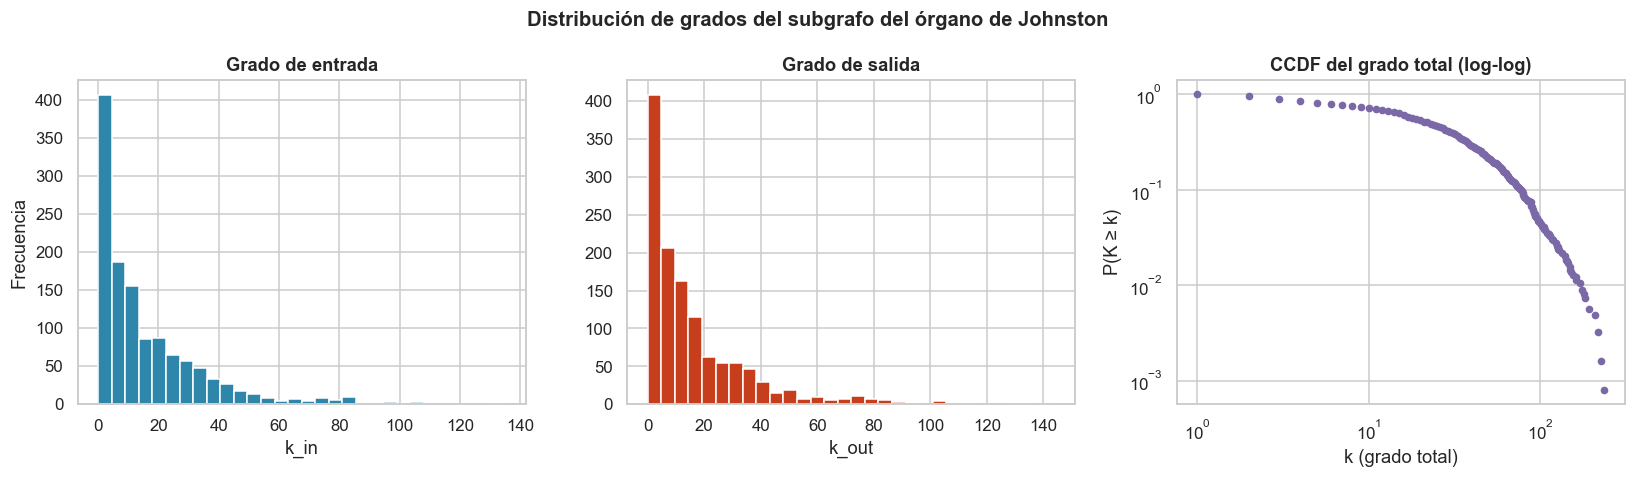

Total degree | mean=32.4  median=22  max=237  skewness=2.12


In [14]:
tot_deg = in_deg + out_deg

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
axes[0].hist(in_deg, bins=30, color=COL_JO, edgecolor="white")
axes[0].set_title("In-degree"); axes[0].set_xlabel("k_in"); axes[0].set_ylabel("Frequency")
axes[1].hist(out_deg, bins=30, color=COL_AMMC, edgecolor="white")
axes[1].set_title("Out-degree"); axes[1].set_xlabel("k_out")

# Complementary cumulative distribution (CCDF) of the total degree, log-log
vals, counts = np.unique(tot_deg, return_counts=True)
ccdf = 1.0 - np.cumsum(counts) / counts.sum() + counts / counts.sum()
axes[2].loglog(vals, ccdf, "o", color="#7B68A6", markersize=4)
axes[2].set_title("CCDF of the total degree (log-log)")
axes[2].set_xlabel("k (total degree)"); axes[2].set_ylabel("P(K ≥ k)")

fig.suptitle("Degree distribution of the Johnston's organ subgraph", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "fig06_degree_distribution.png")
plt.show()

print(f"Total degree | mean={tot_deg.mean():.1f}  median={np.median(tot_deg):.0f}  "
      f"max={tot_deg.max()}  skewness={pd.Series(tot_deg).skew():.2f}")

### 3.3.3. Centrality and hub neurons

Centrality measures point at the most influential neurons of the circuit. We compute three complementary ones. **PageRank** captures global influence taking direction and weight into account, **betweenness** flags the neurons acting as bridges along the information paths, and the plain **total degree** measures raw connectivity. Whatever sits at the top of these rankings is a candidate for coordinating the flow from the auditory circuit into the AMMC.

In [15]:
pagerank = nx.pagerank(G, weight="weight")
betweenness = nx.betweenness_centrality(G, weight=None, seed=SEED)

cent = pd.DataFrame({
    "is_jo": {nid: d.get("is_jo") for nid, d in G.nodes(data=True)},
    "super_class": {nid: d.get("super_class", "") for nid, d in G.nodes(data=True)},
    "k_in": dict(G.in_degree()),
    "k_out": dict(G.out_degree()),
    "pagerank": pagerank,
    "betweenness": betweenness,
})
cent["k_total"] = cent["k_in"] + cent["k_out"]
cent["node_type"] = np.where(cent["is_jo"], "JO (sensory)", "Second-order partner")

print("Top 10 neurons by PageRank:")
top_pr = cent.sort_values("pagerank", ascending=False).head(10)
display(top_pr[["node_type", "super_class", "k_in", "k_out", "pagerank", "betweenness"]].round(5))

print("\nHow much of the total PageRank do the JO neurons hold against their partners?")
print(cent.groupby("node_type")["pagerank"].agg(["count", "sum", "mean"]).round(4))

Top 10 neurons by PageRank:


,tipo,super_class,k_in,k_out,pagerank,betweenness
720575940627015196,Socio 2.º orden,descending,131,10,0.02187,0.00450
720575940610505006,Socio 2.º orden,descending,75,5,0.02099,0.00208
720575940632499757,Socio 2.º orden,descending,90,6,0.01705,0.00520
720575940611644529,Socio 2.º orden,descending,107,5,0.01593,0.00229
720575940622996579,Socio 2.º orden,descending,51,38,0.01312,0.01751
720575940639165247,Socio 2.º orden,visual_centrifugal,6,2,0.01257,0.00001
720575940622838154,Socio 2.º orden,descending,70,10,0.01155,0.00510
720575940624377224,Socio 2.º orden,central,106,112,0.01053,0.02605
720575940635684762,Socio 2.º orden,visual_centrifugal,21,3,0.01049,0.00011
720575940620537153,Socio 2.º orden,central,89,4,0.01036,0.00053



How much of the total PageRank do the JO neurons hold against their partners?
                      count     sum    mean
node_type                                  
JO (sensory)            269  0.0521  0.0002
Second-order partner    970  0.9479  0.0010


### 3.3.4. Communities and excitation/inhibition balance

Running **Louvain modularity** on the weighted undirected version tells us whether the subgraph breaks into modules, a trait typical of biological circuits. The **E/I balance** and the split by **neuropil** then confirm that the subgraph does drain into the AMMC, the entry region of mechanosensory processing.

Communities detected (Louvain): 8  |  modularity Q = 0.411
Sizes of the 5 largest communities: [247, 193, 190, 190, 136]


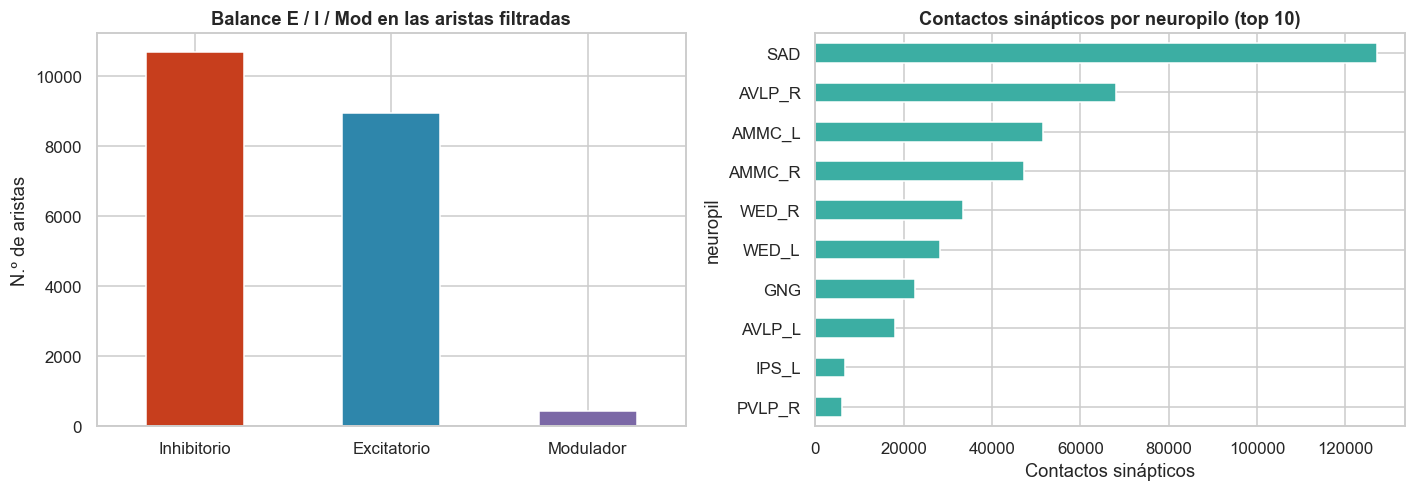


E/I ratio (edges): 0.84  (excitatory=8,940  inhibitory=10,674)


In [16]:
import community as community_louvain  # python-louvain

# Undirected weighted version, used for community detection
G_und_w = nx.Graph()
for u, v, d in G.edges(data=True):
    if G_und_w.has_edge(u, v):
        G_und_w[u][v]["weight"] += d["weight"]
    else:
        G_und_w.add_edge(u, v, weight=d["weight"])

partition = community_louvain.best_partition(G_und_w, weight="weight", random_state=SEED)
modularity = community_louvain.modularity(partition, G_und_w, weight="weight")
n_comms = len(set(partition.values()))
comm_sizes = pd.Series(list(partition.values())).value_counts().sort_values(ascending=False)

print(f"Communities detected (Louvain): {n_comms}  |  modularity Q = {modularity:.3f}")
print(f"Sizes of the 5 largest communities: {comm_sizes.head().tolist()}")

# --- Excitation / inhibition balance and split by neuropil ---
edge_pol = pd.Series([d["polarity"] for *_ , d in G.edges(data=True)]).value_counts()
neuropil_dist = (
    conn_sub[conn_sub["pre_root_id"].isin(final_nodes) & conn_sub["post_root_id"].isin(final_nodes)]
    .groupby("neuropil", observed=True)["syn_count"].sum()
    .sort_values(ascending=False).head(10)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
pol_cols = {"Excitatory": "#2E86AB", "Inhibitory": "#C73E1D",
            "Modulatory": "#7B68A6", "Unknown": "#bbbbbb"}
edge_pol.plot(kind="bar", ax=axes[0], color=[pol_cols.get(k, "#888") for k in edge_pol.index])
axes[0].set_title("E / I / Mod balance across the filtered edges")
axes[0].set_ylabel("Number of edges"); axes[0].tick_params(axis="x", rotation=0)
neuropil_dist.plot(kind="barh", ax=axes[1], color="#3CAEA3")
axes[1].set_title("Synaptic contacts per neuropil (top 10)")
axes[1].set_xlabel("Synaptic contacts"); axes[1].invert_yaxis()
fig.tight_layout()
fig.savefig(OUT_DIR / "fig07_communities_ei_neuropil.png")
plt.show()

exc = edge_pol.get("Excitatory", 0); inh = edge_pol.get("Inhibitory", 0)
print(f"\nE/I ratio (edges): {exc/inh:.2f}  (excitatory={exc:,}  inhibitory={inh:,})")

## 3.4. Drawing the subgraph

We lay the whole circuit out with a force-directed algorithm (`spring_layout`), coloring the **JO sensory neurons** in blue against the **second-order interneurons** in red. Node size is proportional to total degree, so the *hubs* found in the centrality analysis stand out on sight.

Computing the force-directed layout for 1239 nodes...


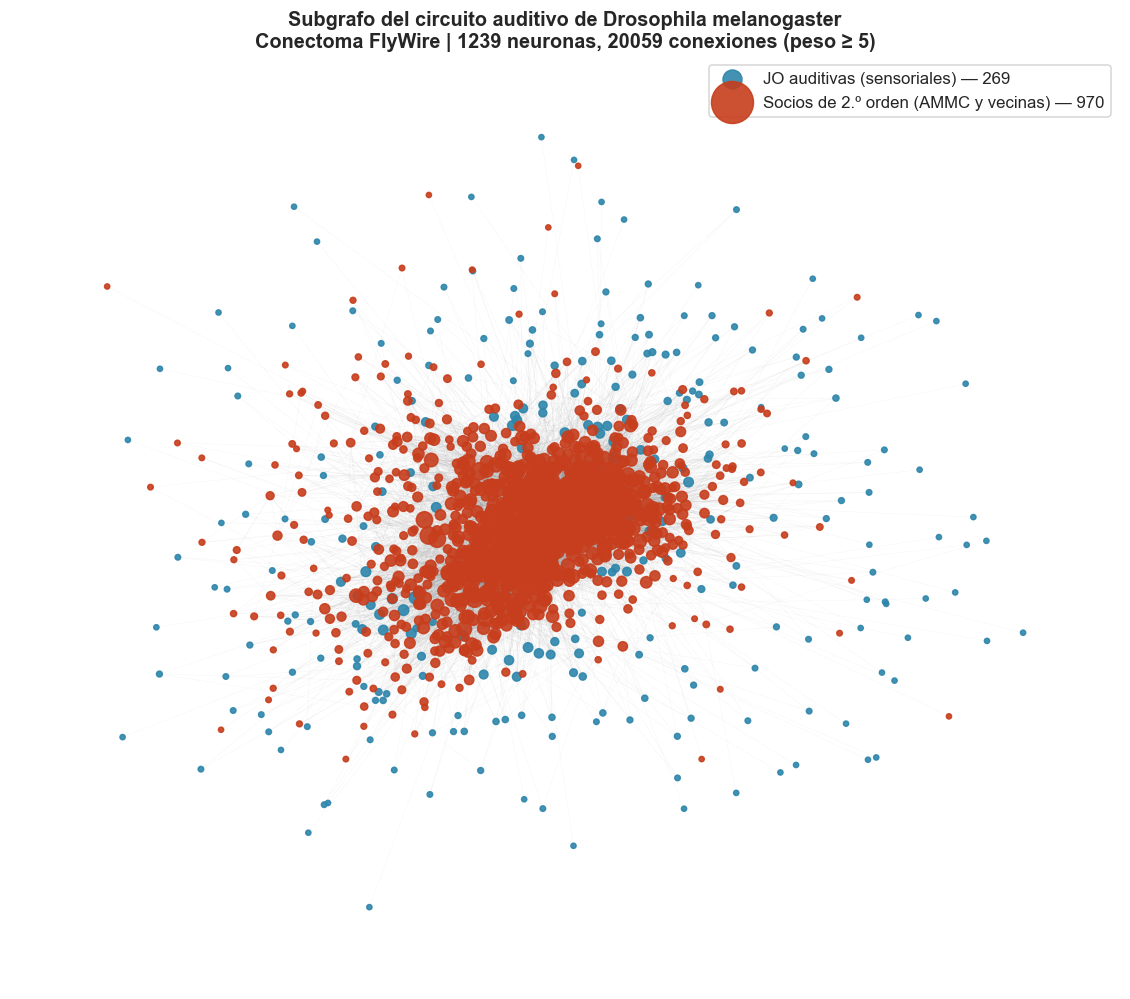

In [17]:
jo_list = [nid for nid, d in G.nodes(data=True) if d.get("is_jo")]
ammc_list = [nid for nid, d in G.nodes(data=True) if not d.get("is_jo")]
deg_map = dict(G.degree())
sizes = {nid: 10 + 1.5 * deg_map[nid] for nid in G.nodes()}

print(f"Computing the force-directed layout for {G.number_of_nodes()} nodes...")
pos = nx.spring_layout(G, k=0.25, iterations=50, seed=SEED)

fig, ax = plt.subplots(figsize=(13, 11))
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.08, width=0.3,
                       edge_color="gray", arrows=False)
nx.draw_networkx_nodes(G, pos, nodelist=jo_list, ax=ax,
                       node_size=[sizes[n] for n in jo_list],
                       node_color=COL_JO, alpha=0.9,
                       label=f"Auditory JO (sensory), {len(jo_list)}")
nx.draw_networkx_nodes(G, pos, nodelist=ammc_list, ax=ax,
                       node_size=[sizes[n] for n in ammc_list],
                       node_color=COL_AMMC, alpha=0.9,
                       label=f"Second-order partners (AMMC and neighbors), {len(ammc_list)}")
ax.set_title("Subgraph of the Drosophila melanogaster auditory circuit\n"
             f"FlyWire connectome | {G.number_of_nodes()} neurons, "
             f"{G.number_of_edges()} connections (weight ≥ {MIN_SYN})", fontsize=13)
ax.legend(loc="upper right", fontsize=11, markerscale=2)
ax.axis("off")
fig.savefig(OUT_DIR / "fig08_jo_subgraph_layout.png")
plt.show()

## 3.5. Building the artificial control network

The experimental design needs a **control network** whose statistical properties match the biological subgraph but whose wiring is drawn at random. Any performance difference measured later can then be attributed to the fine organization of the connections rather than to aggregate properties. We generate the two variants the methodology sets out.

- **Configuration model**, which preserves *exactly* the in- and out-degree sequence of the biological graph.
- **Erdős–Rényi (`G(n, m)`)**, which preserves only the node and edge counts, that is, the density.

Comparing both against the biological graph separates what comes from the degree distribution from what comes from density alone.

In [18]:
# --- Variant 1: directed configuration model (preserves the degree sequence) ---
din = [d for _, d in G.in_degree()]
dout = [d for _, d in G.out_degree()]
G_config = nx.directed_configuration_model(din, dout, seed=SEED)
G_config = nx.DiGraph(G_config)          # collapse multi-edges
G_config.remove_edges_from(nx.selfloop_edges(G_config))

# --- Variant 2: directed Erdős–Rényi (preserves n and m) ---
G_er = nx.gnm_random_graph(n, m, directed=True, seed=SEED)

def quick_stats(graph, name):
    ind = np.array([d for _, d in graph.in_degree()])
    return {
        "Network": name,
        "Nodes": graph.number_of_nodes(),
        "Edges": graph.number_of_edges(),
        "Density": round(nx.density(graph), 4),
        "Mean degree": round(ind.mean(), 2),
        "Reciprocity": round(nx.reciprocity(graph), 4),
        "Clustering": round(nx.average_clustering(graph.to_undirected()), 4),
    }

comparison = pd.DataFrame([
    quick_stats(G, "Biological (JO)"),
    quick_stats(G_config, "Control · configuration"),
    quick_stats(G_er, "Control · Erdős–Rényi"),
]).set_index("Network")
comparison

,Nodos,Aristas,Densidad,Grado medio,Reciprocidad,Agrupamiento
Red,,,,,,
Biológica (JO),1239,20059,0.0131,16.19,0.1287,0.1835
Control · configuración,1239,19313,0.0126,15.59,0.0413,0.0919
Control · Erdős–Rényi,1239,20059,0.0131,16.19,0.0126,0.0258


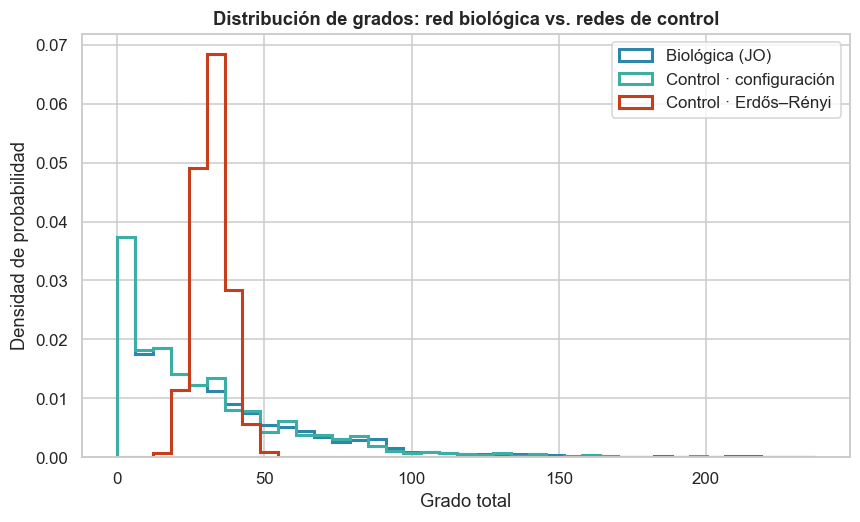

Reading: the configuration model should overlap the biological network (same degree sequence),
while Erdős–Rényi gives a distribution concentrated around the mean degree.


In [19]:
# Degree distribution of the three networks compared
fig, ax = plt.subplots(figsize=(9, 5))
bins = np.linspace(0, max(tot_deg.max(), 1), 40)
for graph, name, color in [
    (G, "Biological (JO)", COL_JO),
    (G_config, "Control · configuration", "#3CAEA3"),
    (G_er, "Control · Erdős–Rényi", COL_AMMC),
]:
    td = np.array([graph.in_degree(x) + graph.out_degree(x) for x in graph.nodes()])
    ax.hist(td, bins=bins, histtype="step", linewidth=2, label=name, color=color, density=True)
ax.set_xlabel("Total degree")
ax.set_ylabel("Probability density")
ax.set_title("Degree distribution: biological network vs. control networks")
ax.legend()
fig.savefig(OUT_DIR / "fig09_control_networks_degree.png")
plt.show()

print("Reading: the configuration model should overlap the biological network (same degree sequence),\n"
      "while Erdős–Rényi gives a distribution concentrated around the mean degree.")

## 3.6. Persisting the deliverables

We save, in open and reproducible formats, the products of phases 2 and 3. That means the node list with its attributes, the filtered edge list, the directed graph in GraphML (readable by Gephi, Cytoscape and NetworkX), the two control networks and a summary of the metrics. These files are the direct input of Component 2, the Brian2 simulation.

In [20]:
# Node list with attributes
nodes_out = pd.DataFrame(
    [{"root_id": nid, **d} for nid, d in G.nodes(data=True)]
).sort_values("is_jo", ascending=False)
nodes_out.to_csv(OUT_DIR / "jo_nodes_filtered.csv", index=False)

# Filtered edge list
edges_out = nx.to_pandas_edgelist(G).rename(columns={"source": "pre", "target": "post"})
edges_out.to_csv(OUT_DIR / "jo_edges_filtered.csv", index=False)

# Directed graph in GraphML
nx.write_graphml(G, OUT_DIR / "jo_subgraph_filtered.graphml")

# Control networks
nx.write_graphml(G_config, OUT_DIR / "control_configuration_model.graphml")
nx.write_graphml(G_er, OUT_DIR / "control_erdos_renyi.graphml")

# Metric summary
summary = {**global_metrics, "synaptic_weight_threshold": MIN_SYN,
           "louvain_communities": n_comms, "modularity_Q": modularity,
           "E_I_ratio": exc / inh if inh else None}
pd.Series(summary).to_csv(OUT_DIR / "summary_metrics.csv", header=["value"])

print(f"Deliverables saved to: {OUT_DIR.resolve()}")
for f in sorted(OUT_DIR.glob("*")):
    print(f"  · {f.name:46s} {f.stat().st_size/1024:8.1f} KB")

Deliverables saved to: /Users/ljmor/Documents/Universidad/Ciclo08/Tesis/flywire-snn-stdp/01-data-understanding/outputs
  · control_configuration_model.graphml               766.6 KB
  · control_erdos_renyi.graphml                       795.1 KB
  · fig01_connectome_superclass_distribution.png       84.9 KB
  · fig02_jo_cell_types.png                            94.5 KB
  · fig03_synaptic_weight_distribution.png            125.5 KB
  · fig04_neurotransmitter_polarity.png                98.3 KB
  · fig05_weight_threshold_sweep.png                  122.0 KB
  · fig06_degree_distribution.png                     100.4 KB
  · fig07_communities_ei_neuropil.png                  84.4 KB
  · fig08_jo_subgraph_layout.png                      844.5 KB
  · fig09_control_networks_degree.png                  70.9 KB
  · jo_edges_filtered.csv                            1116.9 KB
  · jo_nodes_filtered.csv                              61.3 KB
  · jo_subgraph_filtered.graphml                     3830.8 KB

# Conclusions of phases 2 and 3

**Data understanding (phase 2).** The FlyWire connectome holds around 139 000 annotated neurons and tens of millions of connections. Applying the taxonomy of Schlegel et al. (2024) isolated the auditory neurons of the **Johnston's organ** unambiguously (`sensory → mechanosensory → auditory`), and the count we obtained agrees with the anatomical characterization of Kamikouchi et al. (2009). The three diagnostic explorations confirmed that the JO neurons project onto AMMC interneurons and associated regions, that the synaptic weight follows a long-tailed distribution which justifies a filtering threshold, and that the predicted neurotransmitter supports an excitatory/inhibitory assignment dominated by acetylcholine on the excitatory side and by GABA and glutamate on the inhibitory one.

**Data preparation (phase 3).** The threshold sweep supported keeping connections with **≥ 5 synaptic contacts**, a cut that removes the tail of weak connections without disconnecting the circuit or losing JO neurons. The resulting directed subgraph shows a skewed degree distribution with *hubs* (centrality is concentrated), an organization into communities (modularity above zero) and a non-trivial E/I balance. An Erdős–Rényi graph reproduces none of that. The configuration model preserves part of it.

**Deliverables.** The biological subgraph, its two control networks and the metric summary were persisted in open formats, ready to feed Component 2 (SNN simulation in Brian2).

**Methodological traceability.** Every filtering decision was justified with evidence from the previous phase, following the KDD emphasis on data quality before modeling, and the whole process can be reproduced from this notebook plus the raw Codex files.

---

### References

- Dorkenwald, S., et al. (2024). Neuronal wiring diagram of an adult brain. *Nature*.
- Eckstein, N., et al. (2024). Neurotransmitter classification from electron microscopy. *Cell*.
- Kamikouchi, A., et al. (2009). The neural basis of *Drosophila* gravity-sensing and hearing. *Nature*.
- Patella, P., & Wilson, R. I. (2018). Functional maps of mechanosensory features in the *Drosophila* brain. *Current Biology*.
- Schlegel, P., et al. (2024). Whole-brain annotation and multi-connectome cell typing of *Drosophila*. *Nature*.
- Shiu, P. K., et al. (2024). A *Drosophila* computational brain model. *Nature*.